# Tree-Ring: a small demo

In [4]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path('..').resolve()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from api.transformers.tree_ring_watermark import TreeRingWatermarkTransformer

prompt = 'A photo of a red fox in a snowy forest, natural light'
channel = 3

transformer = TreeRingWatermarkTransformer(
    seed=2026,
    watermark_seed=999,
    device='mps',
    model_dtype=torch.float16,
    model_id='sd2-community/stable-diffusion-2-1-base',
    model_revision='4e63672c03103b6c636b8fb4119ba982469b2955',
    watermark_channel=channel,
)

/Users/manoftheprincess/Helloworld/Uni/agh/sem2/watermarks/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading pipeline components...: 100%|██████████| 5/5 [00:00<00:00, 12.85it/s]


## Images and pixel difference

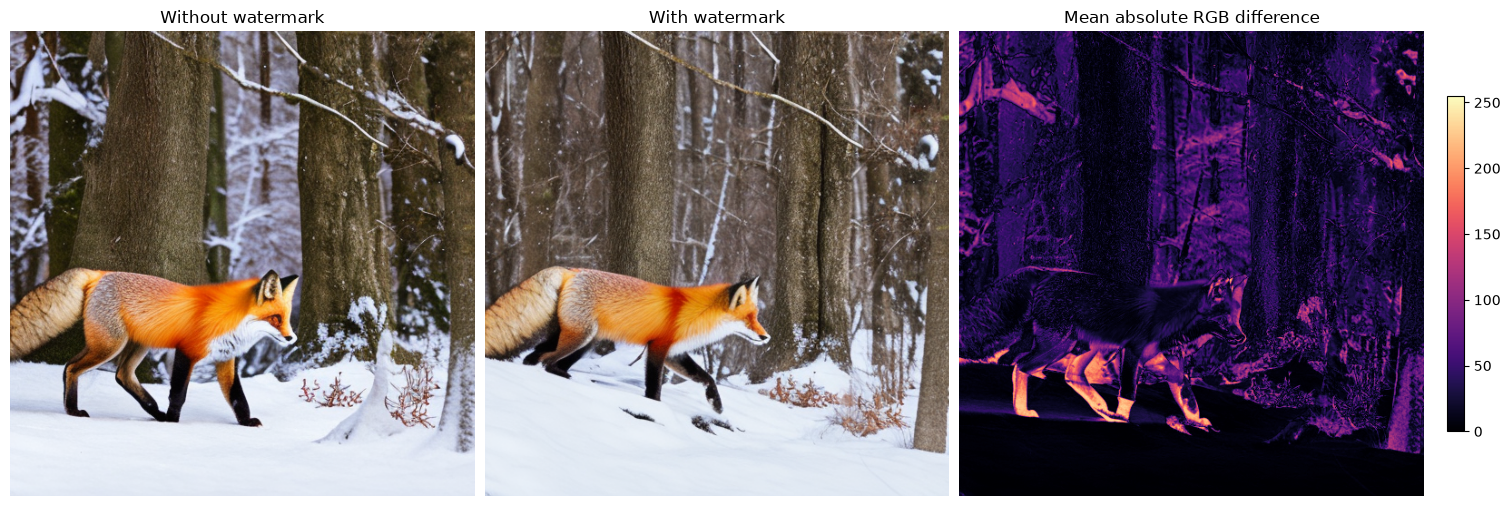

In [5]:
image_plain, noise_plain = transformer.generate(prompt, with_watermark=False)
image_marked, noise_marked = transformer.generate(prompt, with_watermark=True)

difference = np.abs(
    np.asarray(image_marked, dtype=np.float32)
    - np.asarray(image_plain, dtype=np.float32)
).mean(axis=2)

fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
axes[0].imshow(image_plain)
axes[0].set_title('Without watermark')
axes[1].imshow(image_marked)
axes[1].set_title('With watermark')
heatmap = axes[2].imshow(difference, cmap='magma', vmin=0, vmax=255)
axes[2].set_title('Mean absolute RGB difference')
fig.colorbar(heatmap, ax=axes[2], shrink=0.7)
for ax in axes:
    ax.axis('off')
plt.show()

## Key and initial noise spectra

The same key is embedded only in the watermarked branch.

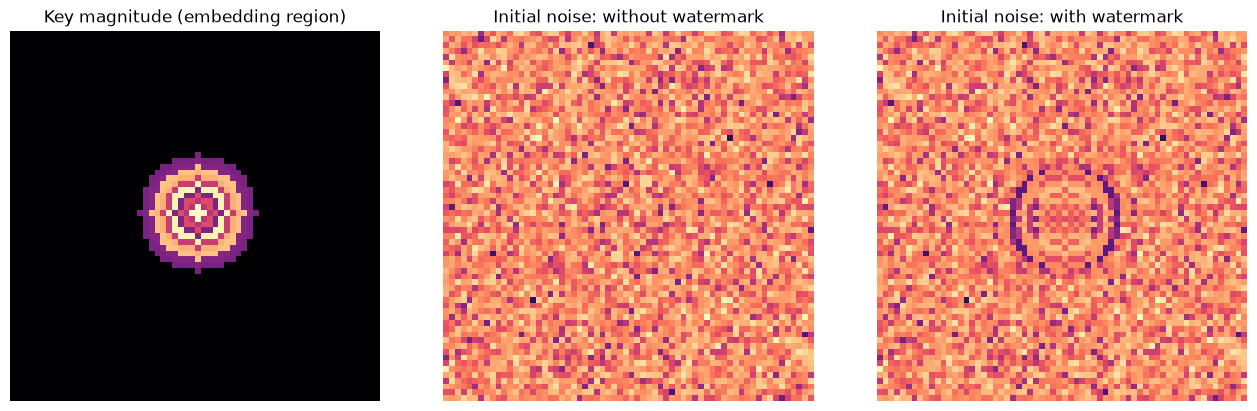

In [6]:
def spectrum(noise):
    values = noise[0, channel].numpy()
    return np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(values))))

plain_spectrum = spectrum(noise_plain)
marked_spectrum = spectrum(noise_marked)
vmax = max(plain_spectrum.max(), marked_spectrum.max())

fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
axes[0].imshow(transformer.watermark.abs().numpy(), cmap='magma')
axes[0].set_title('Key magnitude (embedding region)')
axes[1].imshow(plain_spectrum, cmap='magma', vmin=0, vmax=vmax)
axes[1].set_title('Initial noise: without watermark')
axes[2].imshow(marked_spectrum, cmap='magma', vmin=0, vmax=vmax)
axes[2].set_title('Initial noise: with watermark')
for ax in axes:
    ax.axis('off')
plt.show()

## Detection

Check both images. This is a single-pair demonstration, not an accuracy benchmark.

,distance_l1,p_paper,neg_log10_p,detected
Without watermark,85.121729,1.706962e-01,0.767776,False
With watermark,55.804706,8.072706e-24,23.092981,True


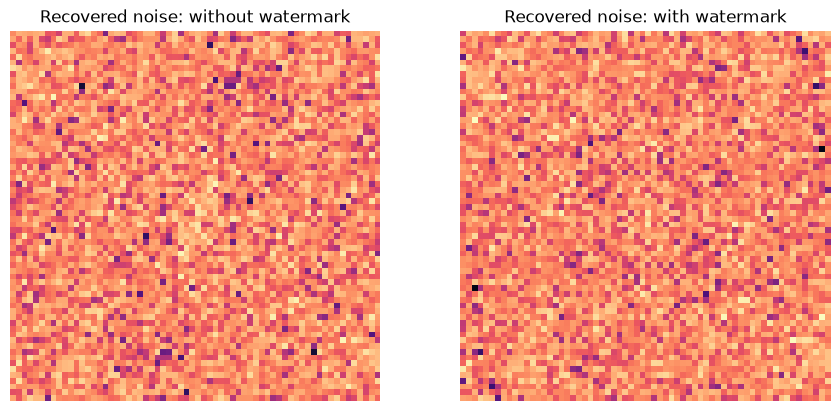

In [7]:
metrics_plain, recovered_plain = transformer.detect(image_plain)
metrics_marked, recovered_marked = transformer.detect(image_marked)

display(pd.DataFrame(
    [metrics_plain, metrics_marked],
    index=['Without watermark', 'With watermark'],
))

plain_spectrum = spectrum(recovered_plain)
marked_spectrum = spectrum(recovered_marked)
vmax = max(plain_spectrum.max(), marked_spectrum.max())

fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
axes[0].imshow(plain_spectrum, cmap='magma', vmin=0, vmax=vmax)
axes[0].set_title('Recovered noise: without watermark')
axes[1].imshow(marked_spectrum, cmap='magma', vmin=0, vmax=vmax)
axes[1].set_title('Recovered noise: with watermark')
for ax in axes:
    ax.axis('off')
plt.show()

In [8]:
checks = pd.Series({
    'Watermarked image detected': bool(metrics_marked['detected']),
    'Unmarked image rejected': not bool(metrics_plain['detected']),
    'Watermarked image closer to key': metrics_marked['distance_l1'] < metrics_plain['distance_l1'],
}, name='Passed')

display(checks.to_frame())
print('PASS' if checks.all() else 'FAIL')

,Passed
Watermarked image detected,True
Unmarked image rejected,True
Watermarked image closer to key,True


PASS
